# Експеримент 3: аналіз помилок

Таблиця з середніми метриками каже, **хто кращий**, але не **чому** і **де** модель помиляється. Тут розбираємо два підходи:
- `jobbert` — `TechWolf/JobBERT-v2`, zero-shot (найкращий за метриками);
- `minilm_ft` — `all-MiniLM-L6-v2` після fine-tuning (`models/minilm_mnrl`, з експерименту 2).

**Питання:**
1. Чи рівномірна якість по посадах, чи є «провальні» посади? Від чого це залежить?
2. Чи відрізняє модель **core** від **contextual**? (Офіційна метрика це враховує: core має вагу 2.)
3. Які саме навички модель хибно ставить на верх (топ-10, яких немає в еталоні)?
4. Чи є посади, де один підхід суттєво кращий за інший?

> **Застереження про еталон.** Оцінки (qrels) для dev-набору створено автоматично (LLM-судд), тож «хибнопозитивні» навички можуть бути правдоподібними, але неоціненими.
> Тому наприкінці зберігаємо вибірку для **ручної** розмітки типів помилок.

In [1]:
import os, sys
from pathlib import Path

# ноутбук лежить в experiments/, а config.py та ranking_metrics.py — в корені проєкту
if not Path("config.py").exists():
    os.chdir(Path.cwd().parent)
sys.path.insert(0, os.getcwd())
print("Робоча папка:", os.getcwd())

Робоча папка: /Users/mac/spj/project/Job-Skill-Matching-Ranking-and-Classification-Using-NLP-Approaches


In [2]:
import ast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

from config import RANDOM_SEED
from ranking_metrics import evaluate_query

VAL_DIR = Path("data/raw/TaskB/validation")
OUT_DIR = Path("results/error_analysis")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "jobbert": "TechWolf/JobBERT-v2",
    "minilm_ft": "models/minilm_mnrl",   # має існувати локально (папка в .gitignore)
}

Matplotlib is building the font cache; this may take a moment.


## 1. Дані
Ті самі dev-файли, що й в усіх експериментах; навичка = перший аліас.

In [3]:
queries = pd.read_csv(VAL_DIR / "queries", sep="\t").rename(columns={"jobtitle": "job_name", "q_id": "job_id"})
corpus = pd.read_csv(VAL_DIR / "corpus_elements", sep="\t").rename(columns={"c_id": "skill_id"})
corpus["skill_aliases"] = corpus["skill_aliases"].apply(ast.literal_eval)
skill_names = corpus["skill_aliases"].apply(lambda x: x[0]).tolist()
qrels = pd.read_csv(VAL_DIR / "qrels.tsv", header=None, sep="\t", names=["job_id", "_", "skill_id", "label"])

skill_index = {sid: i for i, sid in enumerate(corpus["skill_id"])}
grades = {}
for r in qrels.itertuples(index=False):
    grades.setdefault(r.job_id, np.zeros(len(corpus)))[skill_index[r.skill_id]] = r.label

queries = queries[queries["job_id"].isin(grades)].reset_index(drop=True)
job_names = queries["job_name"].tolist()
G = np.vstack([grades[j] for j in queries["job_id"]])   # (посади, навички): 2=core, 1=contextual, 0=решта
print("посад:", len(job_names), "| навичок:", len(skill_names), "| core:", int((G == 2).sum()), "| contextual:", int((G == 1).sum()))

посад: 304 | навичок: 9052 | core: 16161 | contextual: 40257


## 2. Скори обох моделей
`S[модель]` — матриця cosine-схожостей (посади × навички).

In [4]:
S = {}
for short, name in MODELS.items():
    try:
        model = SentenceTransformer(name)
    except Exception as e:
        print(f"ПРОПУСКАЮ {short} ({name}): {type(e).__name__}: {e}")
        continue
    je = model.encode(job_names, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    se = model.encode(skill_names, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    S[short] = je @ se.T
    del model
print("моделі для аналізу:", list(S))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/142 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/142 [00:00<?, ?it/s]

моделі для аналізу: ['jobbert', 'minilm_ft']


## 3. Метрики по кожній посаді
Середні метрики приховують різницю між посадами — дивимось на розподіл.

In [5]:
def per_job_table(scores):
    rows = []
    for i, name in enumerate(job_names):
        m = evaluate_query(scores[i], G[i])
        rows.append({"job": name, "n_core": int((G[i] == 2).sum()), "n_ctx": int((G[i] == 1).sum()), **m})
    return pd.DataFrame(rows)


tables = {k: per_job_table(v) for k, v in S.items()}
(OUT_DIR / "per_job").mkdir(exist_ok=True)
for k, t in tables.items():
    t.to_csv(OUT_DIR / "per_job" / f"{k}.csv", index=False)

summary = pd.DataFrame({k: t["ndcg_graded"].describe() for k, t in tables.items()}).round(3)
summary

,jobbert,minilm_ft
count,304.000,304.000
mean,0.736,0.674
std,0.057,0.078
min,0.430,0.324
25%,0.705,0.638
50%,0.742,0.683
75%,0.771,0.725
max,0.882,0.839


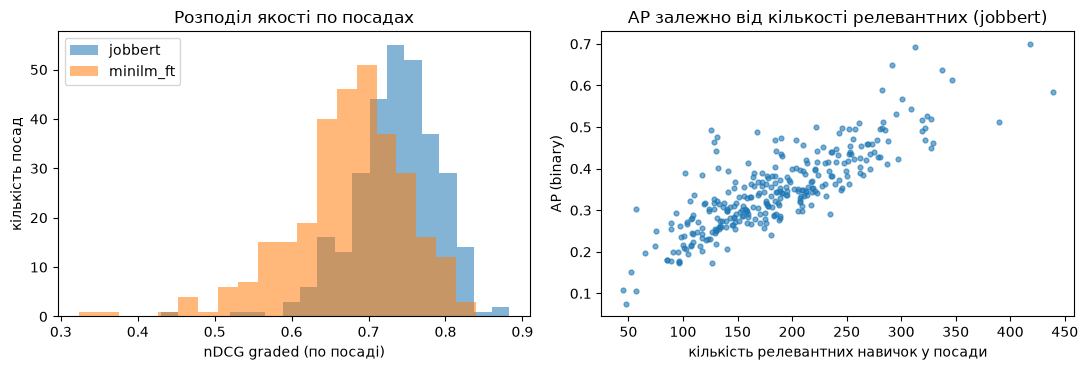

Spearman між n_rel і AP (jobbert): 0.811
Spearman між n_rel і nDCG graded (jobbert): 0.775


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for k, t in tables.items():
    axes[0].hist(t["ndcg_graded"], bins=20, alpha=0.55, label=k)
axes[0].set_xlabel("nDCG graded (по посаді)"); axes[0].set_ylabel("кількість посад"); axes[0].legend()
axes[0].set_title("Розподіл якості по посадах")

best = list(tables)[0]
t = tables[best]
axes[1].scatter(t["n_core"] + t["n_ctx"], t["map_binary"], s=12, alpha=0.6)
axes[1].set_xlabel("кількість релевантних навичок у посади"); axes[1].set_ylabel("AP (binary)")
axes[1].set_title(f"AP залежно від кількості релевантних ({best})")
plt.tight_layout(); plt.show()

t = tables[best].assign(n_rel=lambda d: d["n_core"] + d["n_ctx"])
print(f"Spearman між n_rel і AP ({best}):", round(t["n_rel"].corr(t["map_binary"], method="spearman"), 3))
print(f"Spearman між n_rel і nDCG graded ({best}):", round(t["n_rel"].corr(t["ndcg_graded"], method="spearman"), 3))

## 4. Чи відрізняє модель core від contextual?
- **AUC core-vs-contextual:** ймовірність, що випадкова core-навичка отримала вищий скор, ніж випадкова contextual-навичка тієї самої посади (0.5 = модель не відрізняє).
- **AUC relevant-vs-rest:** те саме для релевантних (core+contextual) проти решти корпусу.
- **Медіанна позиція** у ранжуванні кожної групи (з 9 052).

In [7]:
def pair_auc(a, b):
    """P(a > b) + 0.5 P(a == b) для випадкових елементів a та b."""
    b_sorted = np.sort(b)
    left = np.searchsorted(b_sorted, a, side="left")
    right = np.searchsorted(b_sorted, a, side="right")
    return float(np.mean((left + 0.5 * (right - left)) / len(b)))


rows = []
for k, scores in S.items():
    auc_cx, auc_rest, pos_core, pos_ctx, pos_rest = [], [], [], [], []
    for i in range(len(job_names)):
        s, g = scores[i], G[i]
        order = np.argsort(-s, kind="stable")
        position = np.empty(len(s), dtype=int); position[order] = np.arange(1, len(s) + 1)
        C, X, Z = s[g == 2], s[g == 1], s[g == 0]
        if len(C) and len(X):
            auc_cx.append(pair_auc(C, X))
        if (len(C) + len(X)) and len(Z):
            auc_rest.append(pair_auc(s[g > 0], Z))
        if len(C): pos_core.append(np.median(position[g == 2]))
        if len(X): pos_ctx.append(np.median(position[g == 1]))
        pos_rest.append(np.median(position[g == 0]))
    rows.append({
        "model": k,
        "AUC core>contextual": round(np.mean(auc_cx), 3),
        "AUC relevant>rest": round(np.mean(auc_rest), 3),
        "median pos. core": int(np.mean(pos_core)),
        "median pos. contextual": int(np.mean(pos_ctx)),
        "median pos. rest": int(np.mean(pos_rest)),
    })
pd.DataFrame(rows).set_index("model")

,AUC core>contextual,AUC relevant>rest,median pos. core,median pos. contextual,median pos. rest
model,,,,,
jobbert,0.544,0.959,236,287,4616
minilm_ft,0.602,0.904,403,655,4614


## 5. Найгірші посади: що модель ставить у топ і що пропускає
Для кількох посад із найнижчим nDCG (серед посад з достатньою кількістю релевантних навичок): топ-10 передбачень з позначками та core-навички, які опинились найнижче.

Позначки: `CORE` / `ctx` — є в еталоні; `—` — немає в еталоні (хибнопозитивна або просто не оцінена).

In [8]:
TAG = {2: "CORE", 1: "ctx ", 0: " —  "}


def show_job(model_key, i, top=10, missed=5):
    s, g = S[model_key][i], G[i]
    order = np.argsort(-s, kind="stable")
    t = tables[model_key].iloc[i]
    print(f"\n=== [{model_key}] {job_names[i]} | nDCG={t['ndcg_graded']:.3f} | core={t['n_core']}, ctx={t['n_ctx']} ===")
    print("Топ передбачень:")
    for r, j in enumerate(order[:top], 1):
        print(f"  {r:2d}. [{TAG[int(g[j])]}] {skill_names[j]}  ({s[j]:.2f})")
    core_idx = [j for j in order if g[j] == 2]
    pos = {j: r for r, j in enumerate(order, 1)}
    print(f"Core-навички, що опинились найнижче (з {len(core_idx)}):")
    for j in core_idx[::-1][:missed]:
        print(f"  позиція {pos[j]:5d}: {skill_names[j]}")


MIN_REL = 10
focus = list(tables)[0]
cand = tables[focus][(tables[focus]["n_core"] + tables[focus]["n_ctx"]) >= MIN_REL].sort_values("ndcg_graded")
worst_idx = cand.index[:5].tolist()
for i in worst_idx:
    show_job(focus, i)


=== [jobbert] gl specialist | nDCG=0.430 | core=16, ctx=32 ===
Топ передбачень:
   1. [ —  ] N1QL  (0.53)
   2. [ —  ] prevent money laundering in gambling  (0.40)
   3. [ —  ] teach ESOL language class  (0.38)
   4. [ —  ] good laboratory practice  (0.37)
   5. [ —  ] ensure law application  (0.37)
   6. [ —  ] teach ESOL literacy class  (0.37)
   7. [ —  ] counselling methods  (0.37)
   8. [ —  ] apply GMP  (0.36)
   9. [ —  ] Moodle  (0.35)
  10. [ —  ] analyse logistic needs  (0.35)
Core-навички, що опинились найнижче (з 16):
  позиція  6135: use accounting systems
  позиція  5178: use spreadsheets software
  позиція  3402: information categorisation
  позиція  3069: perform balance sheet operations
  позиція  2433: accounting entries

=== [jobbert] post closer | nDCG=0.540 | core=32, ctx=25 ===
Топ передбачень:
   1. [ —  ] execute opening and closing procedures  (0.58)
   2. [CORE] review closing procedures  (0.56)
   3. [ —  ] postediting  (0.46)
   4. [ —  ] supervise store op

## 6. Де моделі розходяться
Посади, де різниця nDCG між двома підходами найбільша.

In [9]:
if len(tables) >= 2:
    a, b = list(tables)[:2]
    diff = (tables[a]["ndcg_graded"] - tables[b]["ndcg_graded"]).rename(f"{a} − {b}")
    cmp_ = pd.DataFrame({"job": job_names, a: tables[a]["ndcg_graded"].round(3), b: tables[b]["ndcg_graded"].round(3), "diff": diff.round(3)})
    print(f"{a} кращий у {(diff > 0).sum()} посад, {b} кращий у {(diff < 0).sum()} із {len(diff)}")
    print("\nНайбільша перевага", a); display(cmp_.sort_values("diff", ascending=False).head(5))
    print("Найбільша перевага", b); display(cmp_.sort_values("diff").head(5))

jobbert кращий у 263 посад, minilm_ft кращий у 41 із 304

Найбільша перевага jobbert


,job,jobbert,minilm_ft,diff
75,senior sailpoint developer,0.712,0.453,0.259
180,csr coordinator,0.782,0.527,0.255
158,associate technical delivery manager,0.743,0.517,0.226
234,senior microstrategy consultant,0.726,0.510,0.216
255,hazmat specialist,0.798,0.589,0.209


Найбільша перевага minilm_ft


,job,jobbert,minilm_ft,diff
231,math and statistics tutor,0.727,0.803,-0.076
90,trade accountant,0.645,0.709,-0.064
6,market risk analyst,0.659,0.706,-0.047
296,baggage service agent,0.622,0.661,-0.039
50,bindery operator,0.688,0.728,-0.039


## 7. Вибірка для ручної розмітки типів помилок
Береться випадкова вибірка **хибнопозитивних у топ-10** (навичка отримала високий скор, але її немає в еталоні) для моделі `jobbert`.
Файл `results/error_analysis/false_positives_to_annotate.csv` треба відкрити й заповнити колонку `error_type`.

**Пропонована таксономія (команда може її змінити, але визначте її до розмітки):**
- `plausible_unjudged` — навичка правдоподібна для посади, просто немає в еталоні;
- `related_domain` — з суміжної професійної області, але не для цієї посади;
- `generic` — загальна (transversal) навичка, що підходить майже всім;
- `lexical` — збіг слів із назвою посади без смислового зв'язку;
- `other` — інше (коротко поясни в `note`).

Для надійності розмітку краще робити **двом людям незалежно** й порахувати згоду (це вже виходить за рамки стандартного аналізу).

In [10]:
rng = np.random.RandomState(RANDOM_SEED)
rows = []
model_key = list(S)[0]
for i, name in enumerate(job_names):
    s, g = S[model_key][i], G[i]
    order = np.argsort(-s, kind="stable")[:10]
    for r, j in enumerate(order, 1):
        if g[j] == 0:
            rows.append({"model": model_key, "job": name, "skill": skill_names[j], "rank": r, "score": round(float(s[j]), 3)})

fp = pd.DataFrame(rows)
print(f"хибнопозитивних у топ-10 всього: {len(fp)} (з {len(job_names) * 10} позицій)")
sample = fp.sample(n=min(100, len(fp)), random_state=RANDOM_SEED).sort_values(["job", "rank"]).reset_index(drop=True)
sample["error_type"] = ""
sample["note"] = ""
sample.to_csv(OUT_DIR / "false_positives_to_annotate.csv", index=False)
sample.head(10)

хибнопозитивних у топ-10 всього: 1546 (з 3040 позицій)


,model,job,skill,rank,score,error_type,note
0,jobbert,accounting advisor,accounting department processes,7,0.607,,
1,jobbert,administrative assistant / graphic designer,consult team on creative project,8,0.575,,
2,jobbert,affiliate marketing coordinator,execute marketing plan,9,0.585,,
3,jobbert,airman trainee,implement airside safety procedures,8,0.597,,
4,jobbert,assistant director of security,monitor building security,9,0.602,,
5,jobbert,automotive design engineer,design process,10,0.555,,
6,jobbert,baggage service agent,ensure efficient baggage handling,1,0.819,,
7,jobbert,banquet steward,supervise the wine cellar,7,0.549,,
8,jobbert,business development and strategy analyst,carry out strategic research,5,0.630,,
9,jobbert,business development and strategy manager,strategic planning,5,0.614,,
